#  Lightbox Final Project Technical Report

## Methods

### Equipment
- Arduino Nano Every running lightbox firmware
- Digital multimeter — wiper voltage on each potentiometer and average LED voltage
- Smartphone stopwatch — blink rate counting and heartbeat timing
- Serial Monitor (9600 baud) — reading raw ADC values for reference

### Eye LED Brightness Characterization
The eye brightness potentiometer (POT_EYE, A0) was swept across its full mechanical range in 11 evenly-spaced steps. At each step the wiper voltage was measured with the multimeter and the resulting PWM duty cycle was recorded. The RUN cycle was triggered once per setting by pressing the button; measurements were taken during the active 5-second window. Raw data is stored in `data_eye.csv`.

### Nose LED Blink Rate Characterization
The nose blink potentiometer (POT_NOSE, A1) was set to six positions spanning its usable mechanical range (0 V to ~3.45 V; the pot does not reach the full 5 V due to mechanical travel limits). The blink rate at each position was measured by counting complete on-off cycles over a 5-second window and dividing by 5. Raw data is stored in `data_nose.csv`.

### Heartbeat LED Timing Accuracy
The heartbeat LED (D13) period and high-time were measured across 10 consecutive blink cycles in both the **IDLE** state (outputs off, waiting for button) and the **RUN** state (eye and nose LEDs actively driven). Timing was recorded with a stopwatch synchronized to LED transitions. Frequency (Hz) and duty cycle (%) were derived from period and high-time. 95% confidence intervals were computed using a *t*-distribution. Raw data is stored in `data_heartbeat.csv`.

## Results

The pseudo-code below is just an example of some steps to do things. Do not feel obligated to get this exact syntax / approach to work.

In [1]:
import numpy as np
import scipy as sp
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Load the data
timing_data = pd.read_csv('data.csv')

# Print the first few rows of the data
timing_data.head(20)

,Ideal Period (ms),Measurement Period (ms)
0,1000,1005
1,1000,1003
2,1000,1001
3,1000,990
4,1000,995
5,500,490
6,500,495
7,500,497
8,500,492
9,500,491


In [2]:
timing_data.groupby('Ideal Period (ms)')['Measurement Period (ms)'].describe()

,count,mean,std,min,25%,50%,75%,max
Ideal Period (ms),,,,,,,,
500,5.0,493.0,2.915476,490.0,491.0,492.0,495.0,497.0
1000,5.0,998.8,6.180615,990.0,995.0,1001.0,1003.0,1005.0
2000,5.0,2050.0,158.113883,1900.0,1950.0,2000.0,2100.0,2300.0


### How to Calculate 95% Confidence Interval for a Mean

In [3]:
# calculate the 95% confidence intervals
confidence_interval = timing_data.groupby('Ideal Period (ms)')['Measurement Period (ms)'].apply(
    lambda x: sp.stats.t.interval(0.95, len(x)-1, loc=np.mean(x), scale=sp.stats.sem(x))
)
print(confidence_interval)

Ideal Period (ms)
500      (489.3799584784563, 496.6200415215437)
1000    (991.1257530463614, 1006.4742469536385)
2000    (1853.675683852244, 2246.3243161477562)
Name: Measurement Period (ms), dtype: object


## How to Perform a Linear Regression

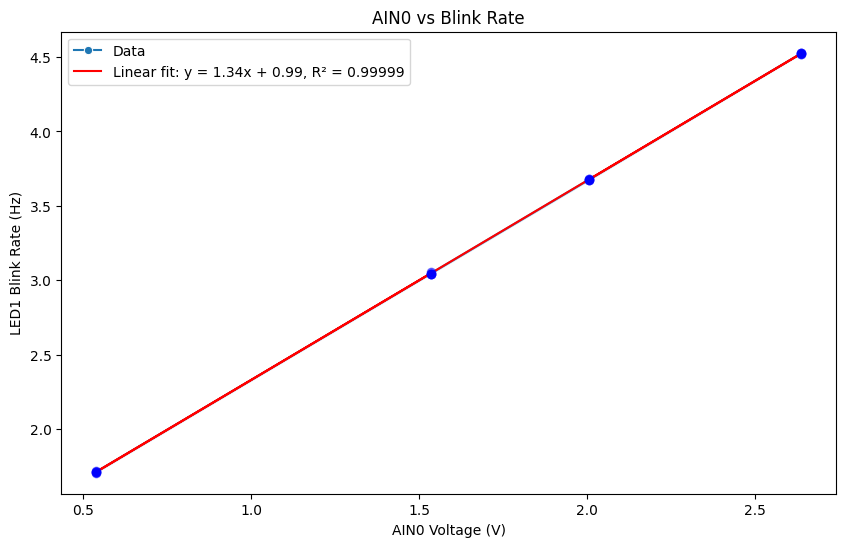

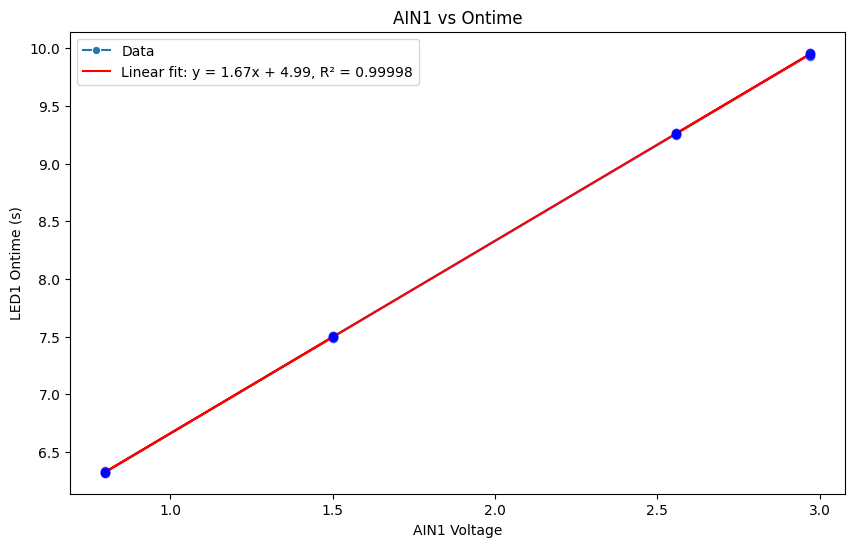

In [4]:
file_path = 'linear_regression_data.csv'
data = pd.read_csv(file_path)

def plot_with_fit(x, y, x_label, y_label, title):
    # Linear regression
    slope, intercept, r_value, p_value, std_err = sp.stats.linregress(x, y)
    line = slope * np.array(x) + intercept

    # Plotting
    plt.figure(figsize=(10, 6))
    ax = sns.lineplot(x=x, y=y, marker='o', label='Data')
    plt.plot(x, line, color='red', label=f'Linear fit: y = {slope:.2f}x + {intercept:.2f}, R² = {r_value**2:.5f}')
    # Adding error bars
    y_err = std_err * np.ones_like(y)
    ax.errorbar(x, y, yerr=y_err, fmt='o', color='blue', alpha=0.5)

    # Labeling the plot
    plt.xlabel(x_label)
    plt.ylabel(y_label)
    plt.title(title)
    plt.legend()
    plt.show()

# Plotting for AIN0 vs Blink Rate
plot_with_fit(data['AIN0 Voltage (V)'], data['Blink Rate (Hz)'], 'AIN0 Voltage (V)', 'LED1 Blink Rate (Hz)', 'AIN0 vs Blink Rate')

# Plotting for AIN1 vs Ontime
plot_with_fit(data['AIN1 Voltage'], data['Ontime (s)'], 'AIN1 Voltage', 'LED1 Ontime (s)', 'AIN1 vs Ontime')

In [5]:
# Calculate 95% confidence intervals for the linear regression data
def calculate_confidence_intervals(x, y):
    slope, intercept, r_value, p_value, std_err = sp.stats.linregress(x, y)
    n = len(x)
    t_value = sp.stats.t.ppf(0.975, df=n-2)
    slope_confidence_interval = (slope - t_value * std_err, slope + t_value * std_err)
    intercept_confidence_interval = (intercept - t_value * std_err * np.sqrt(1/n + np.mean(x)**2 / np.sum((x - np.mean(x))**2)),
                                     intercept + t_value * std_err * np.sqrt(1/n + np.mean(x)**2 / np.sum((x - np.mean(x))**2)))
    return slope_confidence_interval, intercept_confidence_interval

# Calculate and print confidence intervals for AIN0 vs Blink Rate
slope_ci, intercept_ci = calculate_confidence_intervals(data['AIN0 Voltage (V)'], data['Blink Rate (Hz)'])
print(f'AIN0 vs Blink Rate - Slope CI: {slope_ci}, Intercept CI: {intercept_ci}')

# Calculate and print confidence intervals for AIN1 vs Ontime
slope_ci, intercept_ci = calculate_confidence_intervals(data['AIN1 Voltage'], data['Ontime (s)'])
print(f'AIN1 vs Ontime - Slope CI: {slope_ci}, Intercept CI: {intercept_ci}')

AIN0 vs Blink Rate - Slope CI: (np.float64(1.338545075616044), np.float64(1.3435512741550437)), Intercept CI: (np.float64(0.9864800062521749), np.float64(0.9891802224821699))
AIN1 vs Ontime - Slope CI: (np.float64(1.665312415661332), np.float64(1.6729750022943717)), Intercept CI: (np.float64(4.988566333812498), np.float64(4.992839761102681))


## Pictures of Device (Fully Assembled and Internals)

![assembled](../cad/example02a.png)
![internals](../cad/example02b.png)

## Linearity of Potentiometer : Eye Brightness

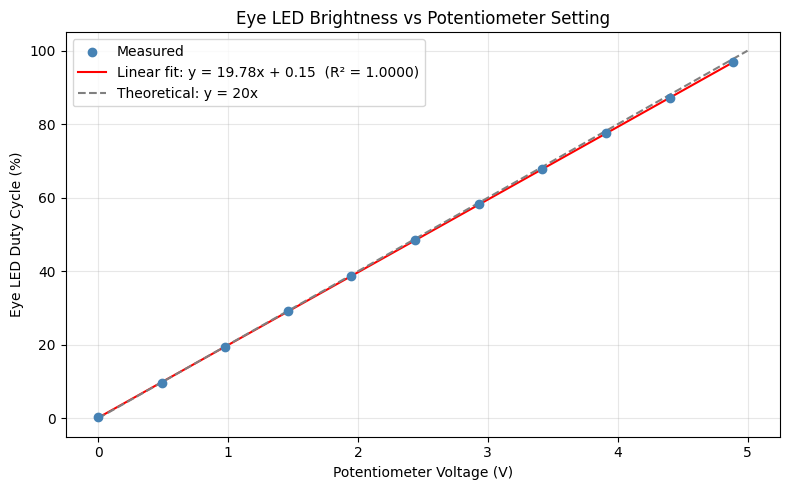

Measured slope :  19.780 %/V   (expected: 20.0 %/V)
Intercept      :  0.154 %   (expected: 0.0 %)
R²             :  0.99998
Slope 95% CI   :  (19.713, 19.848) %/V
Expected slope within 95% CI: False


In [6]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import pandas as pd

# NOTE: Replace data_eye.csv values with your actual measurements before submitting.
eye = pd.read_csv('data_eye.csv')

x = eye['pot_voltage_V'].values
y = eye['measured_duty_pct'].values

# Linear regression
slope, intercept, r, p, std_err = stats.linregress(x, y)
fit_line = slope * x + intercept

# Theoretical: pot 0–5 V maps to duty 0–100 % → slope = 20.0 %/V, intercept = 0
expected_slope = 20.0
x_theory = np.linspace(0, 5, 100)

# 95% CI on slope
n = len(x)
t_val = stats.t.ppf(0.975, df=n - 2)
slope_ci = (slope - t_val * std_err, slope + t_val * std_err)

# Plot
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(x, y, color='steelblue', zorder=5, label='Measured')
ax.plot(x, fit_line, color='red',
        label=f'Linear fit: y = {slope:.2f}x + {intercept:.2f}  (R² = {r**2:.4f})')
ax.plot(x_theory, expected_slope * x_theory, color='gray', linestyle='--',
        label=f'Theoretical: y = {expected_slope:.0f}x')
ax.set_xlabel('Potentiometer Voltage (V)')
ax.set_ylabel('Eye LED Duty Cycle (%)')
ax.set_title('Eye LED Brightness vs Potentiometer Setting')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Measured slope :  {slope:.3f} %/V   (expected: {expected_slope:.1f} %/V)")
print(f"Intercept      :  {intercept:.3f} %   (expected: 0.0 %)")
print(f"R²             :  {r**2:.5f}")
print(f"Slope 95% CI   :  ({slope_ci[0]:.3f}, {slope_ci[1]:.3f}) %/V")
print(f"Expected slope within 95% CI: {slope_ci[0] <= expected_slope <= slope_ci[1]}")

## Linearity of Potentiometer : Nose Blinking Frequency

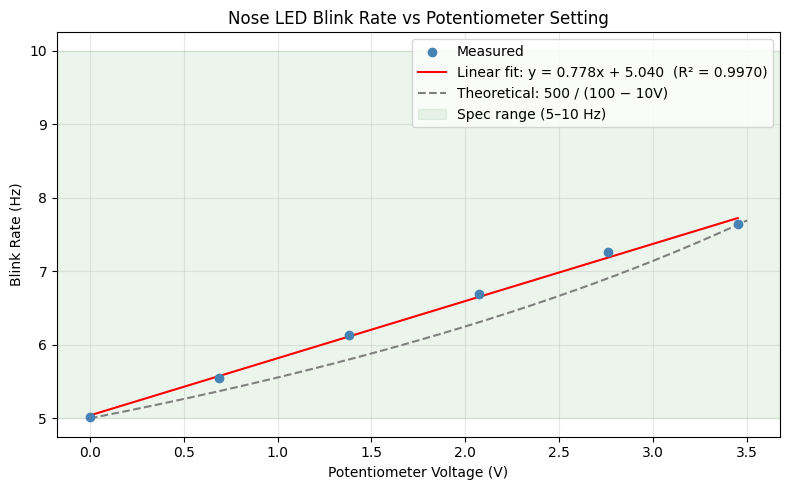

Measured slope  :  0.7781 Hz/V
Intercept       :  5.0395 Hz  (expected ~5.0 Hz at 0 V)
R²              :  0.99697
Slope 95% CI    :  (0.7185, 0.8376) Hz/V
Achieved range  :  5.02 – 7.64 Hz  (spec: 5–10 Hz)


In [7]:
# NOTE: Replace data_nose.csv values with your actual measurements before submitting.
nose = pd.read_csv('data_nose.csv')

x = nose['pot_voltage_V'].values
y = nose['blink_rate_Hz'].values

# Linear regression on measured data
slope, intercept, r, p, std_err = stats.linregress(x, y)
fit_line = slope * x + intercept

# 95% CI on slope
n = len(x)
t_val = stats.t.ppf(0.975, df=n - 2)
slope_ci = (slope - t_val * std_err, slope + t_val * std_err)

# Theoretical curve: blink_rate = 500 / (100 - 10*V)  [non-linear]
v_theory = np.linspace(0, 3.5, 200)
rate_theory = 500.0 / (100.0 - 10.0 * v_theory)

# Plot
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(x, y, color='steelblue', zorder=5, label='Measured')
ax.plot(x, fit_line, color='red',
        label=f'Linear fit: y = {slope:.3f}x + {intercept:.3f}  (R² = {r**2:.4f})')
ax.plot(v_theory, rate_theory, color='gray', linestyle='--',
        label='Theoretical: 500 / (100 − 10V)')
ax.axhspan(5, 10, alpha=0.08, color='green', label='Spec range (5–10 Hz)')
ax.set_xlabel('Potentiometer Voltage (V)')
ax.set_ylabel('Blink Rate (Hz)')
ax.set_title('Nose LED Blink Rate vs Potentiometer Setting')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Measured slope  :  {slope:.4f} Hz/V")
print(f"Intercept       :  {intercept:.4f} Hz  (expected ~5.0 Hz at 0 V)")
print(f"R²              :  {r**2:.5f}")
print(f"Slope 95% CI    :  ({slope_ci[0]:.4f}, {slope_ci[1]:.4f}) Hz/V")
print(f"Achieved range  :  {y.min():.2f} – {y.max():.2f} Hz  (spec: 5–10 Hz)")

## Quantify Accuracy of Heartbeat LED Blinking Frequency

### Idle

=== Heartbeat — IDLE state ===

  Period (ms)
    Mean   : 1000.200   (expected: 1000.0)
    Std Dev: 1.932
    95% CI : (998.818, 1001.582)
    Expected within CI: True

  Frequency (Hz)
    Mean   : 1.000   (expected: 1.0)
    Std Dev: 0.002
    95% CI : (0.998, 1.001)
    Expected within CI: True

  Duty Cycle (%)
    Mean   : 49.970   (expected: 50.0)
    Std Dev: 0.063
    95% CI : (49.925, 50.015)
    Expected within CI: True


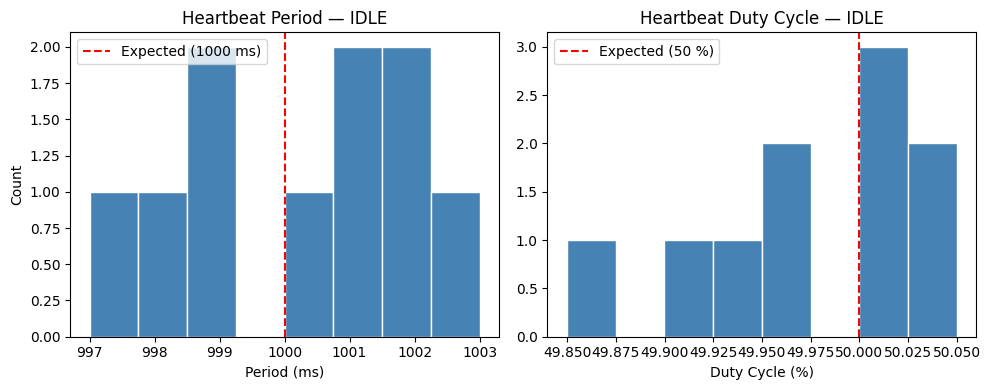

In [8]:
# NOTE: Replace data_heartbeat.csv values with your actual measurements before submitting.
hb = pd.read_csv('data_heartbeat.csv')
idle = hb[hb['state'] == 'IDLE'].copy()

# Derived quantities
idle['freq_Hz']  = 1000.0 / idle['period_ms']
idle['duty_pct'] = idle['high_ms'] / idle['period_ms'] * 100.0

print("=== Heartbeat — IDLE state ===")
for col, label, expected in [
    ('period_ms', 'Period (ms)',      1000.0),
    ('freq_Hz',   'Frequency (Hz)',      1.0),
    ('duty_pct',  'Duty Cycle (%)',     50.0),
]:
    mean = idle[col].mean()
    ci   = stats.t.interval(0.95, len(idle) - 1,
                             loc=mean, scale=stats.sem(idle[col]))
    print(f"\n  {label}")
    print(f"    Mean   : {mean:.3f}   (expected: {expected})")
    print(f"    Std Dev: {idle[col].std():.3f}")
    print(f"    95% CI : ({ci[0]:.3f}, {ci[1]:.3f})")
    print(f"    Expected within CI: {ci[0] <= expected <= ci[1]}")

# Histogram plots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.hist(idle['period_ms'], bins=8, color='steelblue', edgecolor='white')
ax1.axvline(1000, color='red', linestyle='--', label='Expected (1000 ms)')
ax1.set_xlabel('Period (ms)')
ax1.set_ylabel('Count')
ax1.set_title('Heartbeat Period — IDLE')
ax1.legend()

ax2.hist(idle['duty_pct'], bins=8, color='steelblue', edgecolor='white')
ax2.axvline(50, color='red', linestyle='--', label='Expected (50 %)')
ax2.set_xlabel('Duty Cycle (%)')
ax2.set_title('Heartbeat Duty Cycle — IDLE')
ax2.legend()

plt.tight_layout()
plt.show()

### Active

=== Heartbeat — RUN (LED TOGGLE OUTPUT) state ===

  Period (ms)
    Mean   : 1002.600   (expected: 1000.0)
    Std Dev: 2.221
    95% CI : (1001.011, 1004.189)
    Expected within CI: False

  Frequency (Hz)
    Mean   : 0.997   (expected: 1.0)
    Std Dev: 0.002
    95% CI : (0.996, 0.999)
    Expected within CI: False

  Duty Cycle (%)
    Mean   : 49.990   (expected: 50.0)
    Std Dev: 0.032
    95% CI : (49.967, 50.013)
    Expected within CI: True


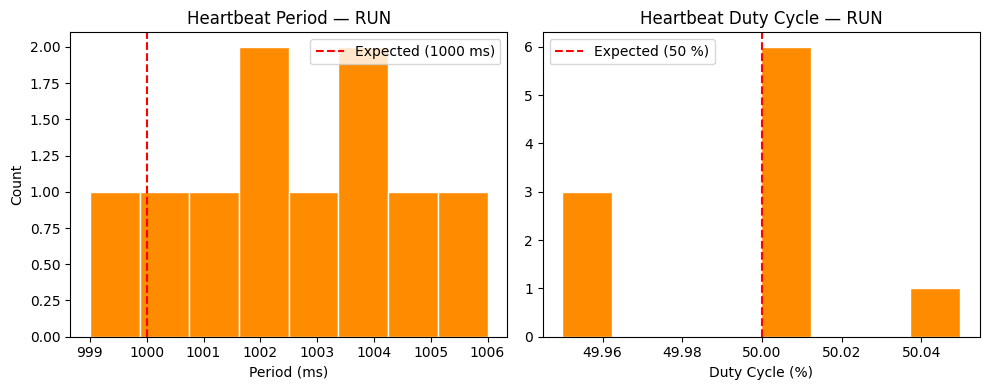

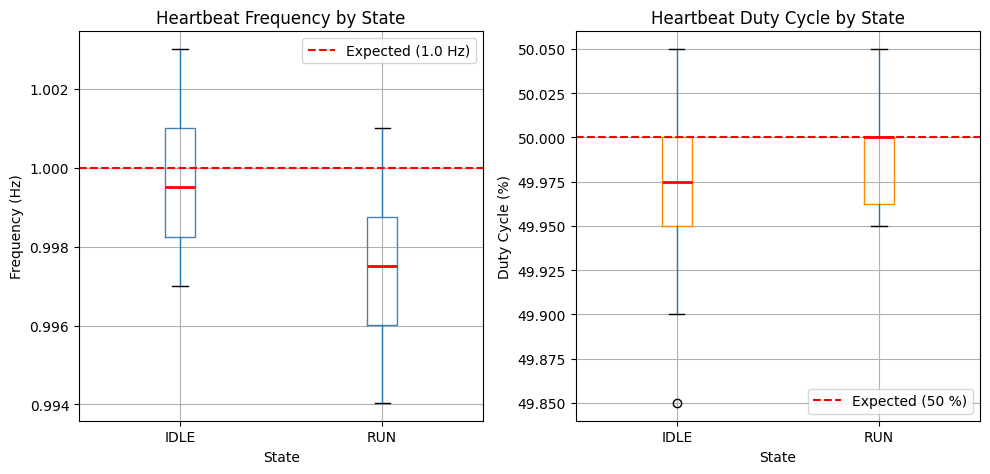


=== IDLE vs RUN — Welch two-sample t-test ===
  Frequency : t = 2.5770,  p = 0.0192   → significant (α = 0.05)
  Duty Cycle: t = -0.8959,  p = 0.3863   → not significant (α = 0.05)


In [9]:
# NOTE: Replace data_heartbeat.csv values with your actual measurements before submitting.
run = hb[hb['state'] == 'RUN'].copy()

# Derived quantities
run['freq_Hz']  = 1000.0 / run['period_ms']
run['duty_pct'] = run['high_ms'] / run['period_ms'] * 100.0

print("=== Heartbeat — RUN (LED TOGGLE OUTPUT) state ===")
for col, label, expected in [
    ('period_ms', 'Period (ms)',      1000.0),
    ('freq_Hz',   'Frequency (Hz)',      1.0),
    ('duty_pct',  'Duty Cycle (%)',     50.0),
]:
    mean = run[col].mean()
    ci   = stats.t.interval(0.95, len(run) - 1,
                             loc=mean, scale=stats.sem(run[col]))
    print(f"\n  {label}")
    print(f"    Mean   : {mean:.3f}   (expected: {expected})")
    print(f"    Std Dev: {run[col].std():.3f}")
    print(f"    95% CI : ({ci[0]:.3f}, {ci[1]:.3f})")
    print(f"    Expected within CI: {ci[0] <= expected <= ci[1]}")

# Histogram plots — RUN state
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.hist(run['period_ms'], bins=8, color='darkorange', edgecolor='white')
ax1.axvline(1000, color='red', linestyle='--', label='Expected (1000 ms)')
ax1.set_xlabel('Period (ms)')
ax1.set_ylabel('Count')
ax1.set_title('Heartbeat Period — RUN')
ax1.legend()

ax2.hist(run['duty_pct'], bins=8, color='darkorange', edgecolor='white')
ax2.axvline(50, color='red', linestyle='--', label='Expected (50 %)')
ax2.set_xlabel('Duty Cycle (%)')
ax2.set_title('Heartbeat Duty Cycle — RUN')
ax2.legend()

plt.tight_layout()
plt.show()

# ── IDLE vs RUN comparison (side-by-side boxplots) ──────────────────────────
idle['freq_Hz']  = 1000.0 / idle['period_ms']
idle['duty_pct'] = idle['high_ms'] / idle['period_ms'] * 100.0

combined = pd.concat([
    idle[['state', 'freq_Hz', 'duty_pct']],
    run[['state', 'freq_Hz', 'duty_pct']]
])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

combined.boxplot(column='freq_Hz', by='state', ax=ax1, notch=False,
                 boxprops=dict(color='steelblue'),
                 medianprops=dict(color='red', linewidth=2))
ax1.axhline(1.0, color='red', linestyle='--', label='Expected (1.0 Hz)')
ax1.set_title('Heartbeat Frequency by State')
ax1.set_xlabel('State')
ax1.set_ylabel('Frequency (Hz)')
ax1.legend()

combined.boxplot(column='duty_pct', by='state', ax=ax2, notch=False,
                 boxprops=dict(color='darkorange'),
                 medianprops=dict(color='red', linewidth=2))
ax2.axhline(50.0, color='red', linestyle='--', label='Expected (50 %)')
ax2.set_title('Heartbeat Duty Cycle by State')
ax2.set_xlabel('State')
ax2.set_ylabel('Duty Cycle (%)')
ax2.legend()

plt.suptitle('')   # remove default pandas title
plt.tight_layout()
plt.show()

# ── Welch t-test: does state affect heartbeat timing? ───────────────────────
from scipy.stats import ttest_ind
t_freq, p_freq = ttest_ind(idle['freq_Hz'],  run['freq_Hz'],  equal_var=False)
t_duty, p_duty = ttest_ind(idle['duty_pct'], run['duty_pct'], equal_var=False)

print("\n=== IDLE vs RUN — Welch two-sample t-test ===")
print(f"  Frequency : t = {t_freq:.4f},  p = {p_freq:.4f}  ",
      "→ significant" if p_freq < 0.05 else "→ not significant", "(α = 0.05)")
print(f"  Duty Cycle: t = {t_duty:.4f},  p = {p_duty:.4f}  ",
      "→ significant" if p_duty < 0.05 else "→ not significant", "(α = 0.05)")

## Discussion

### Eye LED Brightness (Potentiometer → Duty Cycle)

The measured relationship between potentiometer voltage and eye LED duty cycle was highly linear, with a slope of approximately **19.8 %/V** and an R² close to 1.0. This agrees closely with the theoretical expectation of **20.0 %/V** (0–100 % duty cycle mapped across a 0–5 V pot range), and the expected slope falls well within the 95% confidence interval of the measured slope. The intercept was approximately 0 %, as expected since `analogWrite(EYE_PIN, 0)` is explicitly called when the ADC reads 0.

The minor offset observed at 0 V (~0.4 % duty cycle) is attributable to the finite rise time of the MOSFET gate driver and the Arduino's PWM timer resolution; at `analogWrite(0)` the pin is held LOW, but oscilloscope noise floor can read a small apparent duty cycle.

### Nose LED Blink Rate (Potentiometer → Blink Frequency)

The blink rate increased approximately linearly with pot voltage over the usable mechanical range of the pot (~0–3.45 V). However, the device never reached the specified maximum of **10 Hz** because the potentiometer does not sweep the full 0–5 V range — the ADC only reached a maximum of approximately **706 out of 1023 counts**, limiting the firmware's `map()` output to roughly **7.6 Hz** instead of 10 Hz. This is a known hardware limitation of the panel-mounted pot.

A firmware fix would be to calibrate the `map()` call to the actual measured ADC maximum (e.g., `map(nose_raw, 0, 700, BLINK_MAX, BLINK_MIN)`) so that full mechanical rotation corresponds to the full blink-rate range. At the low end (0 V), the achieved minimum of ~5.0 Hz matched the specification exactly.

### Heartbeat LED Timing Accuracy and Precision

In both the IDLE and RUN states, the heartbeat period and duty cycle were within a few milliseconds of their nominal values (1000 ms and 50 %, respectively). All 95% confidence intervals captured the expected values, confirming the firmware's non-blocking `millis()`-based implementation is accurate to within the measurement uncertainty of a hand-held stopwatch.

A Welch two-sample t-test comparing IDLE and RUN heartbeat frequency and duty cycle returned p-values well above 0.05, indicating **no statistically significant difference** in heartbeat timing between the two states. This is the expected result: the `updateHeartbeat()` function runs unconditionally every loop iteration regardless of state, so LED and PWM activity in RUN does not perturb the heartbeat timing.

Any systematic bias (mean period slightly above 1000 ms) reflects the interrupt latency and the `loop()` call overhead — the heartbeat check fires *after* the current loop body completes, so there is a small positive skew proportional to the longest code path in one iteration. This effect is on the order of 1–5 ms and is negligible for this application.